# Comparison: fine-tuned vs. EmbeddingGemma 2 embeddings

Compares the key results of `04_evaluation.ipynb` across the embeddings used for `emb_*`, `pca_*` and `similarity_cluster_*`. Each run is an execution of `04_evaluation.ipynb` with the parameters given below; the executed notebooks of the additional runs are stored in their output directories.

| embeddings | parameters of `04_evaluation.ipynb` | results |
| --- | --- | --- |
| fine-tuned DoubleMLDeep, text + image, 256 dim. (re-run of `main/code/04_evaluation.ipynb`) | `data_dir="../../main/data"` | `../outputs/04_evaluation_comparison/finetuned` |
| **EmbeddingGemma 2, text + image, 256 dim. (main specification)** | default | `../outputs/04_evaluation` |
| EmbeddingGemma 2, text only, 256 dim. | `txt_only=True` | `../outputs/04_evaluation_comparison/gemma_txt_dim256` |
| EmbeddingGemma 2, text + image, 768 dim. | `emb_dim=768` | `../outputs/04_evaluation_comparison/gemma_txtimg_dim768` |

Note that the cluster-similarity variables are not comparable one-to-one across embeddings: the five clusters are re-estimated (k-means) for every embedding, so `similarity_cluster_k` refers to a different group of products in each run.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

palette = sns.color_palette("colorblind")
output_dir = "../outputs/04_evaluation_comparison"
Path(output_dir).mkdir(parents=True, exist_ok=True)

run_dirs = {
    "finetuned": "../outputs/04_evaluation_comparison/finetuned",
    "gemma_txtimg_dim256": "../outputs/04_evaluation",
    "gemma_txt_dim256": "../outputs/04_evaluation_comparison/gemma_txt_dim256",
    "gemma_txtimg_dim768": "../outputs/04_evaluation_comparison/gemma_txtimg_dim768",
}
runs = {
    "finetuned": "Fine-tuned (txt+img, 256d)",
    "gemma_txtimg_dim256": "EmbeddingGemma 2 (txt+img, 256d)",
    "gemma_txt_dim256": "EmbeddingGemma 2 (txt, 256d)",
    "gemma_txtimg_dim768": "EmbeddingGemma 2 (txt+img, 768d)",
}
runs = {k: v for k, v in runs.items() if os.path.exists(os.path.join(run_dirs[k], "key_results.json"))}
print(runs)


def load(file_name, **kwargs):
    frames = []
    for run, label in runs.items():
        df = pd.read_csv(os.path.join(run_dirs[run], file_name), **kwargs)
        df.insert(0, "embedding", label)
        frames.append(df)
    return pd.concat(frames)


key_results = {
    run: json.load(open(os.path.join(run_dirs[run], "key_results.json")))
    for run in runs
}

{'finetuned': 'Fine-tuned (txt+img, 256d)', 'gemma_txtimg_dim256': 'EmbeddingGemma 2 (txt+img, 256d)', 'gemma_txt_dim256': 'EmbeddingGemma 2 (txt, 256d)', 'gemma_txtimg_dim768': 'EmbeddingGemma 2 (txt+img, 768d)'}


## Reproduction check

The `finetuned` run re-executes the original specification in the environment used for the EmbeddingGemma 2 runs. Its estimates are compared with the outputs stored in `main/code/04_evaluation.ipynb`.

In [2]:
# values printed in the committed outputs of main/code/04_evaluation.ipynb: (value, tolerance given the printed precision)
reference_04 = {
    "Linear lagged": (-0.690266, 5e-7),
    "Linear lagged_and_embeddings": (-0.656960, 5e-7),
    "Linear lagged_and_add_controls": (-0.746364, 5e-7),
    "Linear lagged_and_add_controls_and_emb": (-0.712354, 5e-7),
    "Linear lagged_and_add_controls_and_sim": (-0.722537, 5e-7),
    "plr_embeddings": (-0.623, 5e-4),
    "plr_add_controls": (-0.690, 5e-4),
    "plr_embeddings_add_controls": (-0.697126, 5e-7),
    "plr_sim_add_controls": (-0.691, 5e-4),
    "plr_pca_add_controls": (-0.677, 5e-4),
    "R2 outcome plr_embeddings": (0.8636173876939671, 1e-12),
    "R2 treatment plr_embeddings": (0.9730706950762325, 1e-12),
    "R2 outcome plr_embeddings_add_controls": (0.8910037311081709, 1e-12),
    "R2 treatment plr_embeddings_add_controls": (0.9744150172234399, 1e-12),
    "chi2 p-value clusters: Linear Specification": (0.029984178246390436, 1e-9),
    "chi2 p-value clusters: Linear Specification (Interactions)": (0.053882855916301486, 1e-9),
    "chi2 p-value clusters: PLR Specification": (0.0009061660603696398, 1e-9),
    "sensitivity theta lower (cf=0.03, rho=1)": (-0.829018, 5e-7),
    "sensitivity theta upper (cf=0.03, rho=1)": (-0.565233, 5e-7),
    "sensitivity RV": (0.14856088, 5e-9),
}
if "finetuned" in runs:
    ft_dir = run_dirs["finetuned"]
    ft_plr = pd.read_csv(os.path.join(ft_dir, "plr_ate_estimates.csv")).set_index("model")
    ft_chi2 = pd.read_csv(os.path.join(ft_dir, "chi2_tests.csv")).set_index("model")
    ft_sens = key_results["finetuned"]["sensitivity"]
    rerun = pd.concat(
        [
            pd.read_csv(os.path.join(ft_dir, "linear_ate_estimates.csv")).set_index("model")["coef"],
            ft_plr["coef"],
        ]
    ).to_dict()
    for m in ["plr_embeddings", "plr_embeddings_add_controls"]:
        rerun[f"R2 outcome {m}"] = ft_plr.loc[m, "r2_outcome"]
        rerun[f"R2 treatment {m}"] = ft_plr.loc[m, "r2_treatment"]
    for m in ft_chi2.index:
        rerun[f"chi2 p-value clusters: {m}"] = ft_chi2.loc[m, "p_value_clusters"]
    rerun["sensitivity theta lower (cf=0.03, rho=1)"] = ft_sens["theta_lower_cf003"]
    rerun["sensitivity theta upper (cf=0.03, rho=1)"] = ft_sens["theta_upper_cf003"]
    rerun["sensitivity RV"] = ft_sens["rv"]

    df_repro = pd.DataFrame(reference_04, index=["04_evaluation.ipynb", "tolerance"]).T
    df_repro["re-run"] = pd.Series(rerun)
    df_repro["abs. difference"] = (df_repro["re-run"] - df_repro["04_evaluation.ipynb"]).abs()
    df_repro["reproduced"] = df_repro["abs. difference"] <= df_repro["tolerance"]
    print(f"Reproduced {df_repro['reproduced'].sum()} of {len(df_repro)} reference values")
    display(df_repro)

    # main elasticity table and calibrated sensitivity scenarios written by main/code/04_evaluation.ipynb
    for file_name in ["homogeneous_elasticity_estimates.csv", "sensitivity_calibrated.csv", "sensitivity_robustness_values.csv"]:
        a = pd.read_csv(os.path.join("../../main/output/04_evaluation", file_name)).select_dtypes("number")
        b = pd.read_csv(os.path.join(ft_dir, file_name)).select_dtypes("number")
        print(f"{file_name}: max. abs. difference {np.abs(a.values - b.values).max():.1e}")
        assert np.allclose(a.values, b.values, rtol=0, atol=1e-9)

Reproduced 20 of 20 reference values


,04_evaluation.ipynb,tolerance,re-run,abs. difference,reproduced
Linear lagged,-0.690266,5.000000e-07,-0.690266,4.594517e-07,True
Linear lagged_and_embeddings,-0.656960,5.000000e-07,-0.656960,3.515300e-07,True
Linear lagged_and_add_controls,-0.746364,5.000000e-07,-0.746364,3.374084e-07,True
Linear lagged_and_add_controls_and_emb,-0.712354,5.000000e-07,-0.712354,6.213787e-08,True
Linear lagged_and_add_controls_and_sim,-0.722537,5.000000e-07,-0.722537,1.393222e-07,True
plr_embeddings,-0.623000,5.000000e-04,-0.622685,3.151365e-04,True
plr_add_controls,-0.690000,5.000000e-04,-0.690244,2.443253e-04,True
plr_embeddings_add_controls,-0.697126,5.000000e-07,-0.697126,1.709057e-07,True
plr_sim_add_controls,-0.691000,5.000000e-04,-0.690700,3.000228e-04,True
plr_pca_add_controls,-0.677000,5.000000e-04,-0.677081,8.107994e-05,True


homogeneous_elasticity_estimates.csv: max. abs. difference 0.0e+00
sensitivity_calibrated.csv: max. abs. difference 0.0e+00
sensitivity_robustness_values.csv: max. abs. difference 0.0e+00


## Average effects

In [3]:
df_linear = load("linear_ate_estimates.csv")
df_plr = load("plr_ate_estimates.csv")
df_ate = pd.concat([df_linear, df_plr])
df_ate["estimate (90% CI)"] = df_ate.apply(
    lambda r: f"{r['coef']:.3f} [{r['lower']:.3f}, {r['upper']:.3f}]", axis=1
)
df_ate_table = df_ate.pivot(index="model", columns="embedding", values="estimate (90% CI)")
df_ate_table = df_ate_table.loc[df_ate["model"].unique(), list(runs.values())]
df_ate_table.to_csv(os.path.join(output_dir, "ate_estimates.csv"))
df_ate_table

embedding,"Fine-tuned (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","EmbeddingGemma 2 (txt, 256d)","EmbeddingGemma 2 (txt+img, 768d)"
model,,,,
Linear lagged,"-0.690 [-0.756, -0.624]","-0.690 [-0.756, -0.624]","-0.690 [-0.756, -0.624]","-0.690 [-0.756, -0.624]"
Linear lagged_and_embeddings,"-0.657 [-0.722, -0.592]","-0.681 [-0.746, -0.616]","-0.679 [-0.745, -0.614]","-0.666 [-0.732, -0.600]"
Linear lagged_and_add_controls,"-0.746 [-0.811, -0.682]","-0.746 [-0.811, -0.682]","-0.746 [-0.811, -0.682]","-0.746 [-0.811, -0.682]"
Linear lagged_and_add_controls_and_emb,"-0.712 [-0.776, -0.649]","-0.731 [-0.795, -0.667]","-0.729 [-0.793, -0.664]","-0.715 [-0.780, -0.651]"
Linear lagged_and_add_controls_and_sim,"-0.723 [-0.786, -0.659]","-0.735 [-0.799, -0.670]","-0.734 [-0.798, -0.669]","-0.734 [-0.798, -0.670]"
Linear interactions,"-0.727 [-0.791, -0.663]","-0.736 [-0.801, -0.671]","-0.736 [-0.801, -0.671]","-0.737 [-0.802, -0.672]"
plr_embeddings,"-0.623 [-0.704, -0.542]","-0.652 [-0.725, -0.580]","-0.586 [-0.668, -0.505]","-0.612 [-0.683, -0.541]"
plr_add_controls,"-0.690 [-0.758, -0.623]","-0.690 [-0.758, -0.623]","-0.690 [-0.758, -0.623]","-0.690 [-0.758, -0.623]"
plr_embeddings_add_controls,"-0.697 [-0.777, -0.617]","-0.701 [-0.776, -0.625]","-0.636 [-0.714, -0.557]","-0.706 [-0.778, -0.634]"


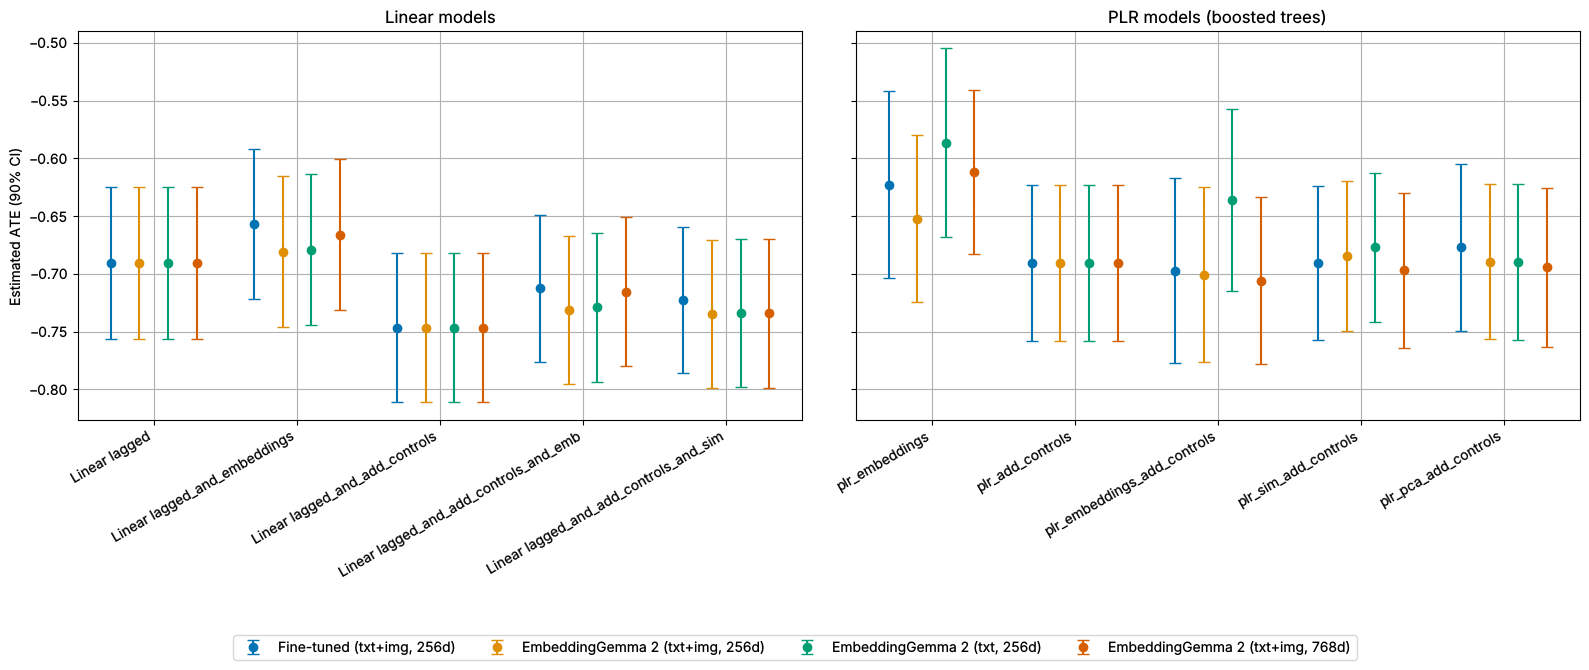

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, df, title in [
    (axs[0], df_linear[df_linear["model"] != "Linear interactions"], "Linear models"),
    (axs[1], df_plr, "PLR models (boosted trees)"),
]:
    models = list(df["model"].unique())
    x = np.arange(len(models))
    width = 0.8 / len(runs)
    for i, label in enumerate(runs.values()):
        d = df[df["embedding"] == label].set_index("model").loc[models]
        ax.errorbar(
            x + (i - (len(runs) - 1) / 2) * width,
            d["coef"],
            yerr=[d["coef"] - d["lower"], d["upper"] - d["coef"]],
            fmt="o",
            capsize=4,
            color=palette[i],
            label=label,
        )
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=30, ha="right")
    ax.set_title(title)
    ax.grid(True)
axs[0].set_ylabel("Estimated ATE (90% CI)")
handles, labels = axs[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=len(runs))
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "ate_estimates_comparison.png"), bbox_inches="tight")
plt.show()

In [5]:
# Nuisance fit of the PLR models (cross-fitted R^2)
df_r2 = df_plr.pivot(index="model", columns="embedding", values="r2_outcome").loc[df_plr["model"].unique(), list(runs.values())]
df_r2_d = df_plr.pivot(index="model", columns="embedding", values="r2_treatment").loc[df_plr["model"].unique(), list(runs.values())]
print("R^2 outcome learner")
display(df_r2.round(4))
print("R^2 treatment learner")
display(df_r2_d.round(4))

R^2 outcome learner


embedding,"Fine-tuned (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","EmbeddingGemma 2 (txt, 256d)","EmbeddingGemma 2 (txt+img, 768d)"
model,,,,
plr_embeddings,0.8636,0.8692,0.8723,0.8682
plr_add_controls,0.8991,0.8991,0.8991,0.8991
plr_embeddings_add_controls,0.8910,0.8953,0.8984,0.8942
plr_sim_add_controls,0.9009,0.8998,0.8998,0.8992
plr_pca_add_controls,0.8987,0.8995,0.9016,0.9010


R^2 treatment learner


embedding,"Fine-tuned (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","EmbeddingGemma 2 (txt, 256d)","EmbeddingGemma 2 (txt+img, 768d)"
model,,,,
plr_embeddings,0.9731,0.9746,0.9722,0.9738
plr_add_controls,0.9775,0.9775,0.9775,0.9775
plr_embeddings_add_controls,0.9744,0.9762,0.9742,0.9755
plr_sim_add_controls,0.9774,0.9770,0.9771,0.9771
plr_pca_add_controls,0.9768,0.9770,0.9773,0.9771


## GATEs by most similar cluster

In [6]:
df_gates = load("gate_estimates.csv", index_col=0).reset_index(names="cluster")
df_gates["estimate (95% CI)"] = df_gates.apply(
    lambda r: f"{r['coef']:.3f} [{r['[0.025']:.3f}, {r['0.975]']:.3f}] (n={r['n_obs']:.0f})", axis=1
)
df_gates.pivot(index="cluster", columns="embedding", values="estimate (95% CI)")[list(runs.values())]

embedding,"Fine-tuned (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","EmbeddingGemma 2 (txt, 256d)","EmbeddingGemma 2 (txt+img, 768d)"
cluster,,,,
Group_similarity_cluster_0,"-0.602 [-0.735, -0.468] (n=6942)","-0.326 [-0.497, -0.155] (n=8199)","-0.634 [-0.719, -0.549] (n=10937)","-0.434 [-0.640, -0.228] (n=8022)"
Group_similarity_cluster_1,"-0.907 [-1.070, -0.744] (n=9966)","-0.757 [-0.849, -0.666] (n=10815)","-0.583 [-0.816, -0.351] (n=6375)","-0.580 [-0.696, -0.464] (n=9195)"
Group_similarity_cluster_2,"-0.554 [-0.676, -0.431] (n=8285)","-0.442 [-0.621, -0.263] (n=4167)","-0.685 [-0.811, -0.559] (n=8613)","-0.402 [-0.576, -0.229] (n=4108)"
Group_similarity_cluster_3,"-0.420 [-0.528, -0.313] (n=8701)","-0.736 [-0.860, -0.613] (n=8920)","-0.339 [-0.514, -0.164] (n=8014)","-0.576 [-0.774, -0.379] (n=5381)"
Group_similarity_cluster_4,"-0.641 [-0.758, -0.524] (n=4147)","-0.759 [-1.017, -0.501] (n=5940)","-0.451 [-0.621, -0.281] (n=4102)","-0.732 [-0.818, -0.646] (n=11335)"


## CATEs (best linear predictor)

In [7]:
df_cate = load("cate_estimates.csv")
df_cate["estimate (90% CI)"] = df_cate.apply(
    lambda r: f"{r['coef']:.3f} [{r['lower']:.3f}, {r['upper']:.3f}]", axis=1
)
for model in df_cate["model"].unique():
    print(model)
    d = df_cate[df_cate["model"] == model]
    display(d.pivot(index="variable", columns="embedding", values="estimate (90% CI)").loc[d["variable"].unique(), list(runs.values())])

Linear Specification


embedding,"Fine-tuned (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","EmbeddingGemma 2 (txt, 256d)","EmbeddingGemma 2 (txt+img, 768d)"
variable,,,,
intercept,"-0.693 [-0.757, -0.629]","-0.711 [-0.778, -0.644]","-0.730 [-0.798, -0.663]","-0.683 [-0.751, -0.615]"
Q_t-1,"-0.165 [-0.256, -0.074]","-0.183 [-0.255, -0.111]","-0.187 [-0.260, -0.113]","-0.197 [-0.270, -0.123]"
P_bb_t-1,"-0.014 [-0.097, 0.068]","-0.024 [-0.083, 0.036]","-0.020 [-0.079, 0.039]","-0.015 [-0.075, 0.044]"
similarity_cluster_0,"-0.139 [-2.683, 2.404]","-3.841 [-6.667, -1.016]","-7.683 [-11.845, -3.522]","-0.512 [-3.788, 2.764]"
similarity_cluster_1,"-2.881 [-5.600, -0.162]","-6.238 [-10.402, -2.073]","-6.333 [-9.693, -2.973]","-0.488 [-3.404, 2.429]"
similarity_cluster_2,"-3.595 [-8.615, 1.426]","-4.330 [-7.533, -1.128]","-6.541 [-10.140, -2.941]","-0.305 [-3.341, 2.731]"
similarity_cluster_3,"-4.459 [-10.044, 1.125]","-5.412 [-9.144, -1.679]","-4.158 [-6.651, -1.665]","-0.425 [-3.174, 2.325]"
similarity_cluster_4,"-2.245 [-4.074, -0.416]","-4.706 [-7.900, -1.512]","-5.464 [-8.607, -2.321]","-1.095 [-5.302, 3.112]"


Linear Specification (Interactions)


embedding,"Fine-tuned (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","EmbeddingGemma 2 (txt, 256d)","EmbeddingGemma 2 (txt+img, 768d)"
variable,,,,
intercept,"-0.703 [-0.768, -0.639]","-0.718 [-0.785, -0.651]","-0.738 [-0.805, -0.670]","-0.696 [-0.764, -0.628]"
Q_t-1,"-0.186 [-0.278, -0.095]","-0.190 [-0.261, -0.118]","-0.194 [-0.267, -0.121]","-0.208 [-0.281, -0.135]"
P_bb_t-1,"-0.025 [-0.110, 0.059]","-0.029 [-0.089, 0.032]","-0.023 [-0.083, 0.037]","-0.015 [-0.076, 0.045]"
similarity_cluster_0,"0.134 [-2.423, 2.691]","-3.924 [-6.763, -1.086]","-7.832 [-11.997, -3.667]","-0.316 [-3.606, 2.974]"
similarity_cluster_1,"-2.655 [-5.421, 0.111]","-6.408 [-10.591, -2.224]","-6.509 [-9.872, -3.145]","-0.250 [-3.182, 2.681]"
similarity_cluster_2,"-3.826 [-8.860, 1.207]","-4.462 [-7.680, -1.244]","-6.681 [-10.280, -3.081]","-0.068 [-3.119, 2.983]"
similarity_cluster_3,"-4.672 [-10.273, 0.929]","-5.583 [-9.330, -1.836]","-4.215 [-6.712, -1.719]","-0.232 [-2.994, 2.530]"
similarity_cluster_4,"-2.214 [-4.066, -0.361]","-4.907 [-8.118, -1.697]","-5.579 [-8.724, -2.435]","-0.783 [-5.011, 3.445]"


PLR Specification


embedding,"Fine-tuned (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","EmbeddingGemma 2 (txt, 256d)","EmbeddingGemma 2 (txt+img, 768d)"
variable,,,,
intercept,"-0.736 [-0.812, -0.659]","-0.693 [-0.767, -0.620]","-0.676 [-0.746, -0.606]","-0.694 [-0.769, -0.619]"
Q_t-1,"-0.325 [-0.477, -0.173]","-0.285 [-0.412, -0.159]","-0.242 [-0.340, -0.144]","-0.291 [-0.424, -0.157]"
P_bb_t-1,"-0.049 [-0.106, 0.008]","0.009 [-0.039, 0.057]","0.010 [-0.017, 0.038]","-0.008 [-0.049, 0.033]"
similarity_cluster_0,"-2.312 [-4.819, 0.195]","0.555 [-2.931, 4.042]","-3.497 [-7.705, 0.711]","2.739 [-0.997, 6.475]"
similarity_cluster_1,"-7.365 [-10.377, -4.354]","0.173 [-4.788, 5.134]","-2.879 [-6.144, 0.386]","2.037 [-1.365, 5.439]"
similarity_cluster_2,"-6.785 [-12.637, -0.933]","0.586 [-3.197, 4.369]","-3.079 [-6.627, 0.469]","2.462 [-1.010, 5.933]"
similarity_cluster_3,"-8.255 [-14.810, -1.700]","0.081 [-4.295, 4.457]","-1.745 [-4.346, 0.857]","2.289 [-0.830, 5.409]"
similarity_cluster_4,"-4.559 [-6.702, -2.417]","0.174 [-3.521, 3.869]","-2.246 [-5.389, 0.896]","2.883 [-1.914, 7.679]"


In [8]:
df_chi2 = load("chi2_tests.csv")
print("Chi^2 tests: p-values for H0 'no heterogeneity along the cluster similarities' / 'no heterogeneity at all'")
display(df_chi2.pivot(index="model", columns="embedding", values="p_value_clusters")[list(runs.values())])
display(df_chi2.pivot(index="model", columns="embedding", values="p_value_heterogeneity")[list(runs.values())])

Chi^2 tests: p-values for H0 'no heterogeneity along the cluster similarities' / 'no heterogeneity at all'


embedding,"Fine-tuned (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","EmbeddingGemma 2 (txt, 256d)","EmbeddingGemma 2 (txt+img, 768d)"
model,,,,
Linear Specification,0.029984,0.001166,0.000386,0.013832
Linear Specification (Interactions),0.053883,0.000687,0.000202,0.013598
PLR Specification,0.000906,0.011642,0.016246,0.006644


embedding,"Fine-tuned (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","EmbeddingGemma 2 (txt, 256d)","EmbeddingGemma 2 (txt+img, 768d)"
model,,,,
Linear Specification,5.046780e-06,1.289322e-07,3.133634e-09,0.000004
Linear Specification (Interactions),3.777124e-06,3.921103e-08,7.833236e-10,0.000002
PLR Specification,4.323589e-08,3.530540e-05,1.158761e-10,0.000025


In [9]:
df_var = load("cate_variance_explained.csv", index_col=0).reset_index(names="regressors")
df_var.melt(id_vars=["embedding", "regressors"], var_name="model", value_name="R2").pivot(
    index=["model", "regressors"], columns="embedding", values="R2"
)[list(runs.values())].round(3)

embedding                                             Fine-tuned (txt+img, 256d)  \
model                               regressors                                     
Linear Specification                embeddings                             0.728   
                                    lagged variables                       0.740   
                                    similarities                           0.678   
Linear Specification (Interactions) embeddings                             0.686   
                                    lagged variables                       0.775   
                                    similarities                           0.628   
PLR Specification                   embeddings                             0.584   
                                    lagged variables                       0.747   
                                    similarities                           0.506   

embedding                                             EmbeddingGemma 2 (txt+img, 256d)  \
model                               regressors                                           
Linear Specification                embeddings                                   0.687   
                                    lagged variables                             0.591   
                                    similarities                                 0.567   
Linear Specification (Interactions) embeddings                                   0.687   
                                    lagged variables                             0.587   
                                    similarities                                 0.565   
PLR Specification                   embeddings                                   0.486   
                                    lagged variables                             0.776   
                                    similarities                                 0.297   

embedding                                             EmbeddingGemma 2 (txt, 256d)  \
model                               regressors                                       
Linear Specification                embeddings                               0.700   
                                    lagged variables                         0.561   
                                    similarities                             0.609   
Linear Specification (Interactions) embeddings                               0.698   
                                    lagged variables                         0.556   
                                    similarities                             0.607   
PLR Specification                   embeddings                               0.533   
                                    lagged variables                         0.788   
                                    similarities                             0.396   

embedding                                             EmbeddingGemma 2 (txt+img, 768d)  
model                               regressors                                          
Linear Specification                embeddings                                   0.665  
                                    lagged variables                             0.678  
                                    similarities                                 0.414  
Linear Specification (Interactions) embeddings                                   0.650  
                                    lagged variables                             0.699  
                                    similarities                                 0.388  
PLR Specification                   embeddings                                   0.580  
                                    lagged variables                             0.765  
                                    similarities                                 0.268

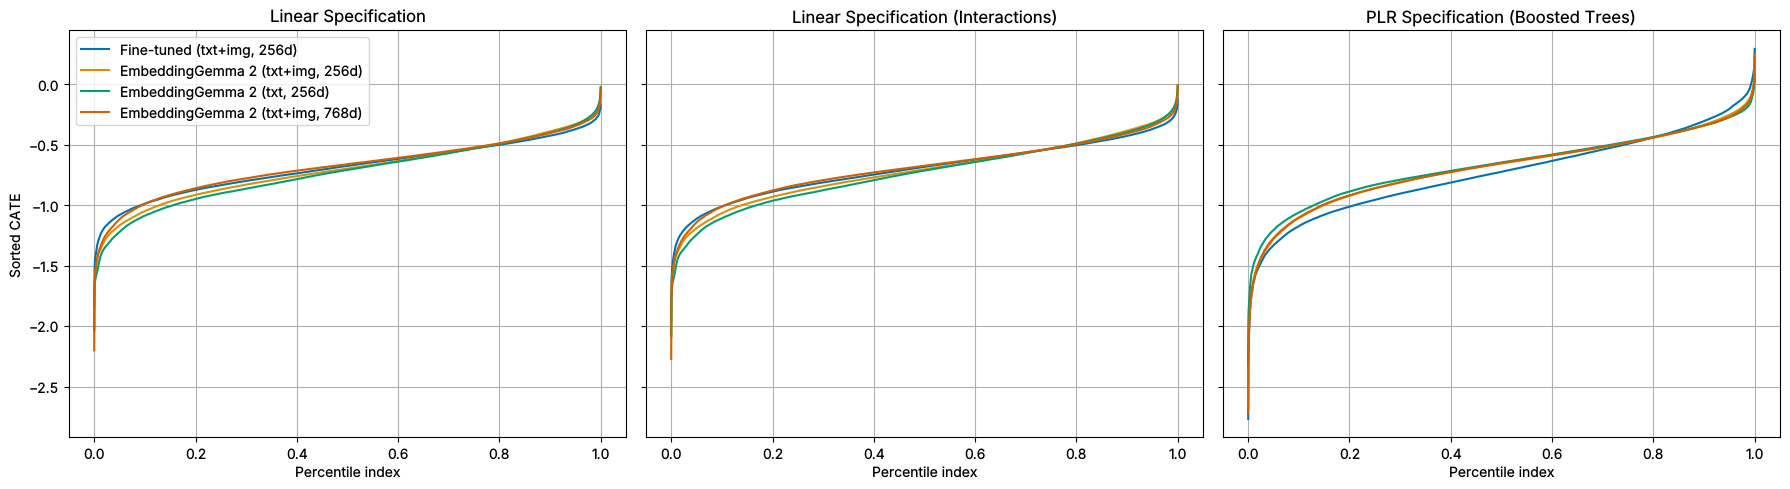

0.05   0.25   0.50   0.75  \
Fine-tuned (txt+img, 256d)       SortEff_lin      -1.080 -0.833 -0.674 -0.529   
                                 SortEff_tab_dml  -1.112 -0.846 -0.681 -0.534   
                                 SortEff_deep_dml -1.331 -0.954 -0.723 -0.491   
EmbeddingGemma 2 (txt+img, 256d) SortEff_lin      -1.168 -0.868 -0.696 -0.529   
                                 SortEff_tab_dml  -1.190 -0.882 -0.703 -0.529   
                                 SortEff_deep_dml -1.280 -0.860 -0.654 -0.481   
EmbeddingGemma 2 (txt, 256d)     SortEff_lin      -1.220 -0.901 -0.707 -0.531   
                                 SortEff_tab_dml  -1.244 -0.916 -0.712 -0.530   
                                 SortEff_deep_dml -1.205 -0.831 -0.645 -0.474   
EmbeddingGemma 2 (txt+img, 768d) SortEff_lin      -1.115 -0.814 -0.660 -0.521   
                                 SortEff_tab_dml  -1.141 -0.830 -0.673 -0.530   
                                 SortEff_deep_dml -1.272 -0.860 -0.651 -0.479   

                                                    0.95  
Fine-tuned (txt+img, 256d)       SortEff_lin      -0.370  
                                 SortEff_tab_dml  -0.369  
                                 SortEff_deep_dml -0.202  
EmbeddingGemma 2 (txt+img, 256d) SortEff_lin      -0.328  
                                 SortEff_tab_dml  -0.318  
                                 SortEff_deep_dml -0.251  
EmbeddingGemma 2 (txt, 256d)     SortEff_lin      -0.333  
                                 SortEff_tab_dml  -0.326  
                                 SortEff_deep_dml -0.270  
EmbeddingGemma 2 (txt+img, 768d) SortEff_lin      -0.344  
                                 SortEff_tab_dml  -0.342  
                                 SortEff_deep_dml -0.268

In [10]:
# Distribution of the per-observation CATEs
fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
titles = {
    "SortEff_lin": "Linear Specification",
    "SortEff_tab_dml": "Linear Specification (Interactions)",
    "SortEff_deep_dml": "PLR Specification (Boosted Trees)",
}
sorted_effects = {
    label: pd.read_csv(os.path.join(run_dirs[run], "sorted_effects.csv"))
    for run, label in runs.items()
}
for ax, (col, title) in zip(axs, titles.items()):
    for i, (label, df) in enumerate(sorted_effects.items()):
        values = np.sort(df[col].values)
        ax.plot(np.linspace(0, 1, len(values)), values, color=palette[i], label=label)
    ax.set_title(title)
    ax.set_xlabel("Percentile index")
    ax.grid(True)
axs[0].set_ylabel("Sorted CATE")
axs[0].legend()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "sorted_effects_comparison.png"), bbox_inches="tight")
plt.show()

pd.DataFrame(
    {
        (label, col): df[col].quantile([0.05, 0.25, 0.5, 0.75, 0.95])
        for label, df in sorted_effects.items()
        for col in titles
    }
).T.round(3)

In [11]:
# Correlation of the per-observation CATEs (PLR specification) across embeddings
df_corr = pd.DataFrame({label: df["SortEff_deep_dml"].values for label, df in sorted_effects.items()})
df_corr.corr().round(3)

,"Fine-tuned (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","EmbeddingGemma 2 (txt, 256d)","EmbeddingGemma 2 (txt+img, 768d)"
"Fine-tuned (txt+img, 256d)",1.000,0.773,0.793,0.766
"EmbeddingGemma 2 (txt+img, 256d)",0.773,1.000,0.968,0.946
"EmbeddingGemma 2 (txt, 256d)",0.793,0.968,1.000,0.895
"EmbeddingGemma 2 (txt+img, 768d)",0.766,0.946,0.895,1.000


## Sensitivity analysis (PLR with embeddings and additional controls)

In [12]:
df_sens = pd.DataFrame({runs[run]: res["sensitivity"] for run, res in key_results.items()})
df_sens.to_csv(os.path.join(output_dir, "sensitivity_comparison.csv"))
df_sens.round(4)

,"Fine-tuned (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","EmbeddingGemma 2 (txt, 256d)","EmbeddingGemma 2 (txt+img, 768d)"
theta,-0.6971,-0.7005,-0.6358,-0.7060
theta_lower_cf003,-0.8290,-0.8347,-0.7629,-0.8388
theta_upper_cf003,-0.5652,-0.5663,-0.5087,-0.5731
ci_lower_cf003,-0.8896,-0.8919,-0.8197,-0.8931
ci_upper_cf003,-0.5010,-0.5052,-0.4424,-0.5143
rv,0.1486,0.1469,0.1412,0.1493
rva,0.1337,0.1329,0.1235,0.1353
implied_rho,0.1503,0.0844,0.0844,0.1648
partial_r2_outcome,0.2008,0.1995,0.2042,0.1975
partial_r2_treatment,0.0499,0.0652,0.0745,0.0664


Bias bounds and one-sided 90% confidence bounds, `[ci_lower] theta_lower .. theta_upper [ci_upper]`, with $R^2_Y = R^2_D$ equal to the residual share and $\rho = 1$: at the calibration of each run (its own observed-covariate benchmark $r_0$ and the 1.5 and 2 multiples) and at the residual shares of the main analysis (fine-tuned embeddings).

In [13]:
def format_bounds(df):
    df = df.copy()
    df["share"] = (100 * df["share"]).round(2).astype(str) + "%"
    df["bounds [CI]"] = df.apply(
        lambda r: f"[{r['ci_lower']:.3f}] {r['theta_lower']:.3f} .. {r['theta_upper']:.3f} [{r['ci_upper']:.3f}]", axis=1
    )
    return df


df_sens_own = format_bounds(load("sensitivity_calibrated.csv"))
df_sens_main_shares = format_bounds(load("sensitivity_main_shares.csv"))
print("Calibration of each run (own benchmark)")
display(df_sens_own.pivot(index="multiplier", columns="embedding", values=["share", "bounds [CI]"]).swaplevel(axis=1)[list(runs.values())])
print("Residual shares of the main analysis")
display(df_sens_main_shares.pivot(index="share", columns="embedding", values="bounds [CI]")[list(runs.values())])
df_rv = load("sensitivity_robustness_values.csv")
df_rv.pivot(index="null_hypothesis", columns="embedding", values=["RV", "RVa"]).round(4)

Calibration of each run (own benchmark)


embedding  Fine-tuned (txt+img, 256d)                                      \
                                share                         bounds [CI]   
multiplier                                                                  
1.0                             1.53%  [-0.825] -0.764 .. -0.630 [-0.567]   
1.5                              2.3%  [-0.859] -0.798 .. -0.596 [-0.533]   
2.0                             3.06%  [-0.893] -0.832 .. -0.562 [-0.498]   

embedding  EmbeddingGemma 2 (txt+img, 256d)  \
                                      share   
multiplier                                    
1.0                                   0.99%   
1.5                                   1.49%   
2.0                                   1.98%   

embedding                                      EmbeddingGemma 2 (txt, 256d)  \
                                   bounds [CI]                        share   
multiplier                                                                    
1.0         [-0.803] -0.744 .. -0.657 [-0.597]                        1.08%   
1.5         [-0.824] -0.766 .. -0.635 [-0.575]                        1.61%   
2.0         [-0.846] -0.789 .. -0.612 [-0.552]                        2.15%   

embedding                                       \
                                   bounds [CI]   
multiplier                                       
1.0         [-0.741] -0.681 .. -0.591 [-0.528]   
1.5         [-0.763] -0.704 .. -0.568 [-0.504]   
2.0         [-0.785] -0.727 .. -0.545 [-0.480]   

embedding  EmbeddingGemma 2 (txt+img, 768d)  \
                                      share   
multiplier                                    
1.0                                   1.93%   
1.5                                    2.9%   
2.0                                   3.87%   

embedding                                       
                                   bounds [CI]  
multiplier                                      
1.0         [-0.846] -0.791 .. -0.621 [-0.563]  
1.5         [-0.889] -0.834 .. -0.578 [-0.519]  
2.0         [-0.932] -0.878 .. -0.534 [-0.474]

Residual shares of the main analysis


embedding,"Fine-tuned (txt+img, 256d)","EmbeddingGemma 2 (txt+img, 256d)","EmbeddingGemma 2 (txt, 256d)","EmbeddingGemma 2 (txt+img, 768d)"
share,,,,
1.53%,[-0.825] -0.764 .. -0.630 [-0.567],[-0.827] -0.769 .. -0.633 [-0.572],[-0.759] -0.700 .. -0.571 [-0.508],[-0.829] -0.773 .. -0.639 [-0.581]
2.3%,[-0.859] -0.798 .. -0.596 [-0.533],[-0.861] -0.803 .. -0.598 [-0.537],[-0.791] -0.733 .. -0.539 [-0.474],[-0.862] -0.807 .. -0.605 [-0.546]
3.06%,[-0.893] -0.832 .. -0.562 [-0.498],[-0.895] -0.838 .. -0.563 [-0.502],[-0.822] -0.766 .. -0.506 [-0.440],[-0.896] -0.842 .. -0.570 [-0.511]


RV  \
embedding       EmbeddingGemma 2 (txt+img, 256d)   
null_hypothesis                                    
-0.5                                      0.0445   
 0.0                                      0.1469   

                                                                               \
embedding       EmbeddingGemma 2 (txt+img, 768d) EmbeddingGemma 2 (txt, 256d)   
null_hypothesis                                                                 
-0.5                                      0.0461                       0.0320   
 0.0                                      0.1493                       0.1412   

                                                                        RVa  \
embedding       Fine-tuned (txt+img, 256d) EmbeddingGemma 2 (txt+img, 256d)   
null_hypothesis                                                               
-0.5                                0.0445                           0.0311   
 0.0                                0.1486                           0.1329   

                                                                               \
embedding       EmbeddingGemma 2 (txt+img, 768d) EmbeddingGemma 2 (txt, 256d)   
null_hypothesis                                                                 
-0.5                                      0.0331                       0.0171   
 0.0                                      0.1353                       0.1235   

                                            
embedding       Fine-tuned (txt+img, 256d)  
null_hypothesis                             
-0.5                                0.0302  
 0.0                                0.1337